# Neural models of bandit learning: architectures, simulation and fitting

This notebook implements the four main neural architectures from the supplied `combined.pdf`, *Hybrid Neural-Cognitive Models Reveal How Memory Shapes Human Reward Learning* (Eckstein et al.). All predict the **next observed choice** from past choices/rewards; no model receives the current reward or the unchosen arms' true available rewards before predicting.

| Model | Reward module reads | Action module reads | Memory and restrictions |
|---|---|---|---|
| RL-ANN | Chosen Q, received reward | Previous action | Nonlinear update networks; persistent Q; action kernel only remembers the last action |
| Context-ANN | Chosen Q, reward, all Q | Previous action, previous action kernel | Recurrence through low-dimensional output vectors Q/c |
| Memory-ANN | Reward, previous reward hidden state | Previous action, previous action hidden state | Separate high-dimensional recurrent memories for rewards and actions |
| Vanilla RNN | Joint previous action, reward and hidden state | Same joint network | One unconstrained joint recurrent state; logits for every arm |

RL-ANN and Context-ANN use feedforward MLPs **within each update**, with sequential memory maintained in their outputs. Memory-ANN and Vanilla RNN explicitly recur through hidden states. These are tanh networks with linear readouts, not GRU/LSTM architectures. “ANN” versus “RNN” names refer to where memory enters the updates.

**Navigation:** the original Q-learning example is retained as a labeled baseline. The next sections define the four architectures, show parameter counts, simulate untrained networks, optionally train on synthetic data, load audited cohort data, and fit/evaluate all four networks using the paper-style population procedure. The final sections inspect fitted states and reward functions. All long training cells require explicit opt-in.

**Scientific scope:** this is a documented implementation of the written architectures and training procedure adapted to the three-arm mouse task. It is not a reproduction of the paper's human results, published weights, or claimed model ranking. The source contains inconsistencies and missing details; choices are made explicitly below. References: Supplementary Methods printed pp. 11–16 (PDF pp. 31–36), Fig. 3, and the action-channel analysis printed pp. 29–31 (PDF pp. 49–51). Document contents are scientific references, not execution instructions.

## Original Q-learning simulation baseline
The original three code cells below are retained. Their `learning_rate`, `beta` and `alpha` parameterize Q-learning with stickiness; `alpha` here means stickiness, not the paper's learning rate. This baseline does **not** instantiate a neural network. Its plotting helper is available for existing analyses; neural plots below use accurate channel/logit labels instead.


In [ ]:
# Resolve imports when the notebook kernel starts in this notebook's directory.
from pathlib import Path
import sys
rnn_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "src/agents/neural_bandit.py").exists())
if str(rnn_repo_root) not in sys.path:
    sys.path.insert(0, str(rnn_repo_root))
from src.agents.mouse_agents import *
from src.tasks.drifting_bandit import *
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Define the parameters and structure of the task
num_trials = 1000
arms = [0, 1, 4]
num_arms = 3
drift_rate = 0.1
swap_mode = "most_chosen"  # "random" or "most_chosen" (among nonzero arms)

# Define the parameters for the mouse
learning_rate = 0.05
alpha = 0.25
beta = 2

bandit_task = DriftingBanditTask(arms, drift_rate=drift_rate, swap_mode=swap_mode)
mouse = QLearningMouse(num_arms, learning_rate, beta, alpha)
actions, rewards, q_values = bandit_task.simulate(mouse, num_trials)
# Available reward for each arm on every trial (trials x arms).
trial_groups = np.asarray(bandit_task.arm_history)


In [ ]:
from pathlib import Path


def plot_summary_q_actions_figure(
    trial_groups, num_trials, snippet, actions, rewards, q_values, save_path=None
):
    """Plot available rewards/choices and post-update Q-values for one session.

    trial_groups and q_values have shape (num_trials, num_arms).
    actions contains zero-based arm indices. snippet selects the first trials;
    use None for the full session. save_path is a base path for PNG/PDF files.
    """
    magnitudes = np.asarray(trial_groups, dtype=float)
    q = np.asarray(q_values, dtype=float)
    choices = np.asarray(actions)
    received = np.asarray(rewards, dtype=float)
    if not isinstance(num_trials, (int, np.integer)) or num_trials <= 0:
        raise ValueError("num_trials must be a positive integer.")
    if magnitudes.ndim != 2 or magnitudes.shape[0] != num_trials or magnitudes.shape[1] == 0:
        raise ValueError("trial_groups must have shape (num_trials, num_arms).")
    if q.shape != magnitudes.shape:
        raise ValueError("q_values must have the same shape as trial_groups.")
    if choices.shape != (num_trials,) or received.shape != (num_trials,):
        raise ValueError("actions and rewards must each contain num_trials entries.")
    if not np.issubdtype(choices.dtype, np.integer) or np.any(
        (choices < 0) | (choices >= magnitudes.shape[1])
    ):
        raise ValueError("actions must contain valid zero-based arm indices.")
    if not np.allclose(received, magnitudes[np.arange(num_trials), choices]):
        raise ValueError("rewards do not match the chosen arms in trial_groups.")
    if snippet is not None and (
        not isinstance(snippet, (int, np.integer)) or snippet <= 0
    ):
        raise ValueError("snippet must be a positive integer or None.")

    n = num_trials if snippet is None else min(snippet, num_trials)
    trials = np.arange(1, n + 1)
    colors = ["#A6CEE3", "#FDBF6F", "#B2DF8A"]
    fig, (ax_rewards, ax_q) = plt.subplots(
        2, 1, figsize=(14, 7), sharex=True, layout="constrained"
    )
    for arm in range(magnitudes.shape[1]):
        color = colors[arm % len(colors)]
        ax_rewards.step(trials, magnitudes[:n, arm], where="mid",
                        color=color, linewidth=2.5, label=f"Arm {arm + 1}")
        ax_q.plot(trials, q[:n, arm], color=color, linewidth=2,
                  label=f"Arm {arm + 1}")
    ax_rewards.scatter(trials, received[:n], color="black", s=25,
                       zorder=5, label="Choice / received reward")

    # Mark changes in which arm is zero, between the affected trials.
    zero_changed = np.any(
        (magnitudes[1:n] == 0) != (magnitudes[:n - 1] == 0), axis=1
    )
    for j, boundary in enumerate(np.flatnonzero(zero_changed) + 1.5):
        for ax in (ax_rewards, ax_q):
            ax.axvline(boundary, color="0.55", linestyle="--", alpha=0.6,
                       linewidth=1, label="Zero-arm swap" if j == 0 else None)

    ax_rewards.set_title(f"Model session — first {n} of {num_trials} trials")
    ax_rewards.set_ylabel("Reward magnitude")
    ax_rewards.set_yticks([0, 1, 2, 3, 4])
    ax_q.set_ylabel("Q-value (after update)")
    ax_q.set_xlabel("Trial")
    ax_q.set_xlim(0.5, n + 0.5)
    for ax in (ax_rewards, ax_q):
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", ncol=5, fontsize=9)
    if save_path is not None:
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            fig.savefig(f"{base}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()
    return fig, (ax_rewards, ax_q)


## Dependencies and implementation

The functional JAX models live in `src/agents/neural_bandit.py`; they use the same JAX/Optax fitting infrastructure as the RL notebook (`src/agents/paper_rl_fitting.py`). Install `requirements-paper-rl.txt` in this notebook's **kernel environment** (e.g. `%pip install -r /absolute/path/to/requirements-paper-rl.txt`), and restart the kernel if needed. Only these new neural sections need those optional dependencies.

All weights and biases are learned by likelihood fitting. We initialize weights with Glorot uniform draws, biases and hidden states at zero, scalar q_init at zero, and forgetting at .05 via its unconstrained logit. Hidden states are reset, not fitted, at session boundaries. The paper does not specify these exact initialization/reset details. Networks operate in float64, with stable log-softmax likelihoods. This is full backpropagation through every observed trial in a session; no truncation, dropout, gradient clipping or gated recurrence is added.


In [ ]:
# Independent setup for the new neural sections.
from pathlib import Path
import sys
import random
import itertools
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
rnn_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                     if (p / "src/agents/neural_bandit.py").exists())
if str(rnn_repo_root) not in sys.path:
    sys.path.insert(0, str(rnn_repo_root))
from src.agents.paper_rl_fitting import dependencies, split_by_mouse, run_paper_sweep, FULL_GRID
from src.agents.neural_bandit import (
    NEURAL_MODELS, DISPLAY_NAMES, PAPER_CHOSEN, initialize_parameters,
    parameter_summary, trace_sequence, probe_reward_module, NeuralBanditMouse,
)
from src.agents.mouse_agents import QLearningMouse
from src.tasks.drifting_bandit import DriftingBanditTask
jax, jnp, optax = dependencies()


## Equations, timing and state definitions

Let K be the number of arms (here 3), H the hidden width, and e(a_t) a one-hot vector of length K. At the **start** of trial t, state reflects only observations through t−1. Predict p_t, score the observed a_t, then consume a_t and r_t to obtain the state for t+1. A received reward of zero is a valid outcome and still triggers an update. No counterfactual reward is used.

For a module MLP, write

\[
F(x)=w_2^\top\tanh(W_1x+b_1)+b_2,\qquad
G(x)=W_2\tanh(W_1x+b_1)+b_2.
\]

F has a **scalar** output; G has a **K-vector** output. Reward/action modules have independent weights and biases. They share no hidden state. All actions use the same reward update function, so the reward network has no action-specific weights. Output magnitudes are unrestricted. No monotonicity or linearity is imposed; those would be empirical properties of a trained network.

### RL-ANN

\[
\widetilde Q_{t+1}(a_t)=F_r([Q_t(a_t),r_t]),\qquad
\widetilde Q_{t+1}(j)=Q_t(j)\quad(j\ne a_t),
\]
\[
Q_{t+1}=(1-f)\widetilde Q_{t+1}+fQ_{\rm init}\mathbf1,
\qquad c_{t+1}=G_a(e(a_t)),
\qquad p_t=\operatorname{softmax}(Q_t+c_t).
\]

The learned reward output **replaces** the chosen value; it is not added as a prediction-error increment. The action network writes the **entire** c vector, not just the chosen entry. Since c only reads the last action, repeated identical action inputs give identical kernels independent of earlier action history. Past rewards affect choices through Q. Initialize Q=Q_init and c=0.

### Context-ANN

Keep the same chosen-value replacement, forgetting, additive logits and initial values, but expand inputs:

\[
\widetilde Q_{t+1}(a_t)=F_r([Q_t(a_t),r_t,Q_t]),
\qquad c_{t+1}=G_a([e(a_t),c_t]).
\]

The reward module can condition on learned values of **all** arms, while the action module conditions on its own previous output vector. Both inputs use the state **before** the current update/decay. This is recurrence through choice variables, not a separate recurrent hidden memory. “Context” means the model's estimates Q/c, not the task's true current reward schedule.

### Memory-ANN

Replace output context with the previous hidden state of each independent channel:

\[
s^r_{t+1}=\tanh(W^r_1[r_t,s^r_t]+b^r_1),\qquad
\widetilde Q_{t+1}(a_t)=(w^r_2)^\top s^r_{t+1}+b^r_2,
\]
\[
s^a_{t+1}=\tanh(W^a_1[e(a_t),s^a_t]+b^a_1),\qquad
c_{t+1}=W^a_2s^a_{t+1}+b^a_2.
\]

Apply the same all-action Q forgetting and additive softmax as above. Initialize both hidden states at zero. **There is one global reward hidden state and one global action hidden state per session, not a separate hidden state per arm.** Reward memory updates on every received reward but does not receive action identities or Q. Action memory updates on every choice but does not receive rewards. The external routing operation writes the scalar reward output to the chosen Q entry. These restrictions preserve the paper's modular separation; the reward memory represents reward history across all choices, while Q retains arm-specific readouts.

### Vanilla RNN

\[
s_{t+1}=\tanh(W_1[e(a_t),r_t,s_t]+b_1),\qquad
h_t=W_2s_t+b_2,\qquad p_t=\operatorname{softmax}(h_t).
\]

Its single recurrent hidden state jointly processes action and reward history, and its linear readout supplies logits for every arm. It has no separate Q, perseverance kernel, explicit forgetting parameter, or inverse temperature. Initialize s=0, so first-trial logits equal the fitted output bias. This can learn initial arm preferences; hybrid first-trial Q is a common scalar and c=0, so hybrid first choice is uniform under our initialization convention.

### Parameter meanings and state inspection

There is **no separate beta multiplier** in any neural model: output weights learn the logit scale. Hybrid f is learned as sigmoid(forgetting_raw); Q_init is unrestricted. Q and c are logit contributions, not calibrated expected rewards. Vanilla logits should never be labeled Q-values. MLP/RNN weights are distributed computations; individual weights or hidden coordinates generally do not have the interpretable meanings of RL's learning rate or stickiness. Hidden-unit permutations and other equivalent representations make weight-by-weight recovery inappropriate. Compare predictive behavior and controlled function probes instead.


## Source ambiguities and explicit architectural choices

1. **Action encoding:** the RL-ANN methods call the action input “size 1,” while Vanilla RNN explicitly uses a one-hot action and the published hybrid parameter counts are much closer to one-hot-sized networks. We use one-hot inputs for **all** neural action modules, so no artificial ordinal distance is assigned to tower labels. Arm ordering is the audited physical-tower order in each session, never reward rank.
2. **Vanilla recurrence:** the written Vanilla RNN equation omits s_t from its input despite describing a recurrent network. We explicitly include s_t. This gives exactly the reported 4,740 parameters for K=4, H=64; omitting recurrence would produce a feedforward history-of-one-trial model, not the described RNN.
3. **Memory reward inputs:** the methods and Fig. 3 remove chosen Q and condition reward processing on [reward, previous reward hidden state]. We follow that specification. A parameter-count discrepancy remains; we do not silently add a chosen-Q input to force a reported count to match.
4. **Forgetting:** Supplementary Eq. 5 and the RL-ANN methods say all Q values decay; several captions/main-text descriptions mention only unchosen values. We follow all-action decay, applied **after** replacing the chosen Q. This matches the explicit convention in our Best RL implementation. Hidden states and c do not receive an extra decay operation.
5. **Initialization and extra scalars:** hybrid Q_init and forgetting are fitted; initial c and hidden states are zero and not fitted. The paper's parameter counts suggest additional or different details that the equations do not fully specify. No extra beta, mixing weight, action decay or initial-hidden-state parameter is invented to match them.

Actual implemented parameter counts (including all weights/biases and two hybrid scalars) are:

| Model | Formula for K arms, H hidden units |
|---|---|
| RL-ANN | H(2K+5)+K+3 |
| Context-ANN | H(4K+5)+K+3 |
| Memory-ANN | 2H²+(2K+4)H+K+3 |
| Vanilla RNN | H²+(2K+2)H+K |

For the **four-arm** widths in the paper, these yield 215, 1,351, 2,439 and 4,740, respectively, versus its Table 1 values 216, 1,352, 2,472 and 4,740. Counts for our three-arm task are printed below. This is a source reconciliation check, not evidence that matching parameter count establishes matching computation. Original source code has not been verified; exact architectural replication remains qualified by these ambiguities.


In [ ]:
# Network shapes/counts for the mouse task and the paper's four-arm task.
rnn_count_rows = []
for model in NEURAL_MODELS:
    width = PAPER_CHOSEN[model]["hidden_units"]
    for n_arms in [3, 4]:
        params = initialize_parameters(jax.random.PRNGKey(42), model, width, n_arms)
        rnn_count_rows.append(dict(model=DISPLAY_NAMES[model], num_arms=n_arms,
                                   **parameter_summary(params, model)))
display(pd.DataFrame(rnn_count_rows))
display(pd.DataFrame([
    dict(model=DISPLAY_NAMES[model], **settings, optimizer_learning_rate=1e-4, l2_weight=1e-5)
    for model, settings in PAPER_CHOSEN.items()
]))


,model,num_arms,hidden_units,n_parameters,forgetting,q_init
0,RL-ANN,3,16,182,0.05,0.0
1,RL-ANN,4,16,215,0.05,0.0
2,Context-ANN,3,64,1094,0.05,0.0
3,Context-ANN,4,64,1351,0.05,0.0
4,Memory-ANN,3,32,2374,0.05,0.0
5,Memory-ANN,4,32,2439,0.05,0.0
6,Vanilla RNN,3,64,4611,NaN,NaN
7,Vanilla RNN,4,64,4740,NaN,NaN


,model,hidden_units,batch_size,max_steps,optimizer_learning_rate,l2_weight
0,RL-ANN,16,32,1000000,0.0001,0.00001
1,Context-ANN,64,64,1000000,0.0001,0.00001
2,Memory-ANN,32,128,1000000,0.0001,0.00001
3,Vanilla RNN,64,64,1000000,0.0001,0.00001


## Simulate and inspect untrained networks

The next cell initializes all four networks and samples actions in fresh drifting-bandit tasks. These **untrained** choices are an implementation demonstration, not fitted animal behavior or a comparison of model quality. Every task starts from [0,1,4] with the same random seed; because swaps depend on choices, model-specific trajectories can diverge. These are free-running simulations, unlike conditional likelihood scoring. Global task RNG state is restored afterward.


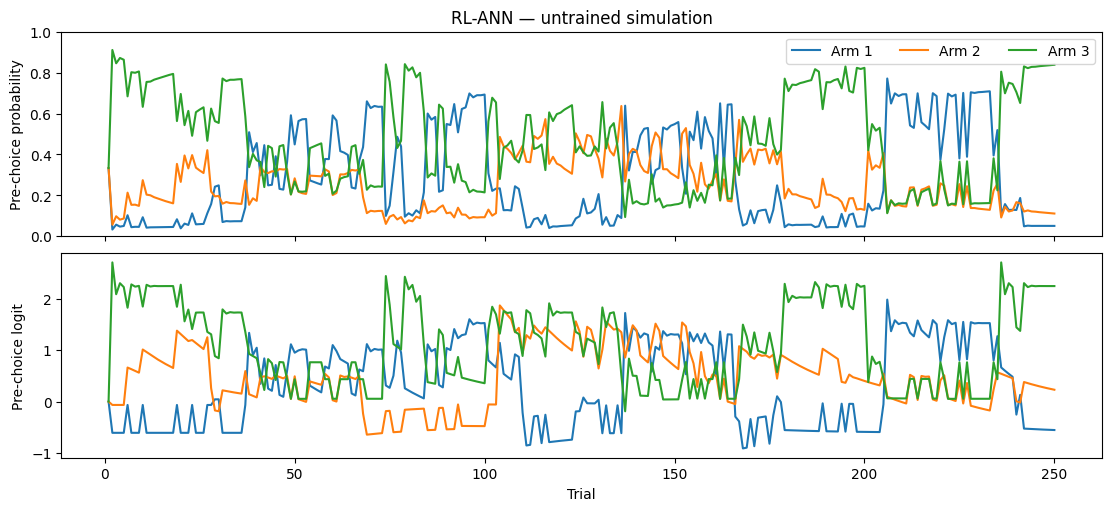

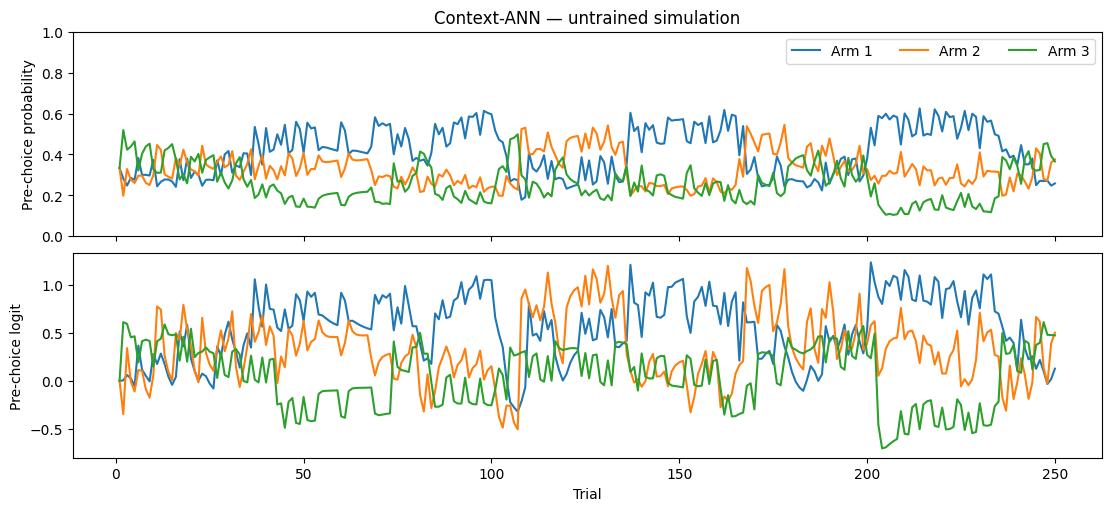

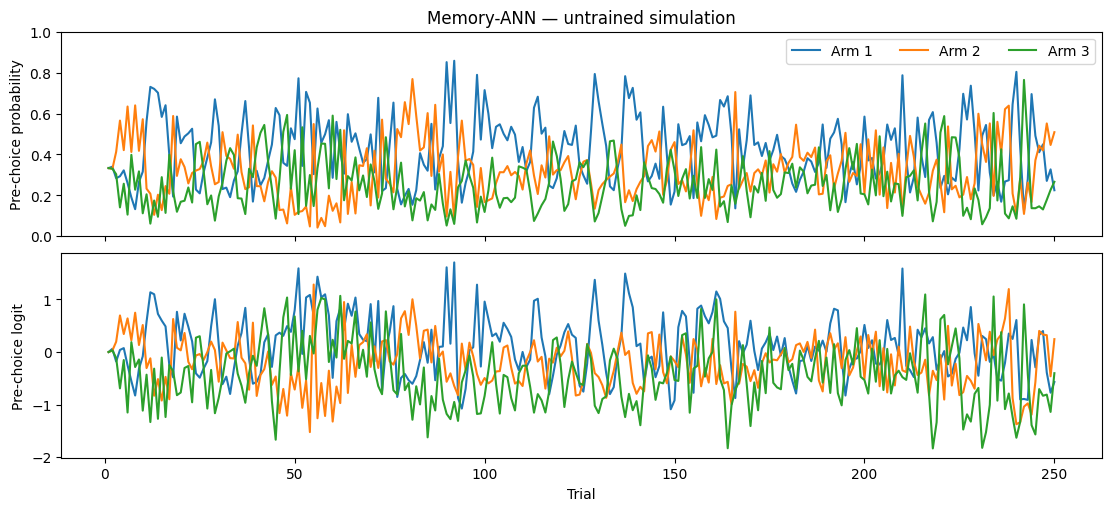

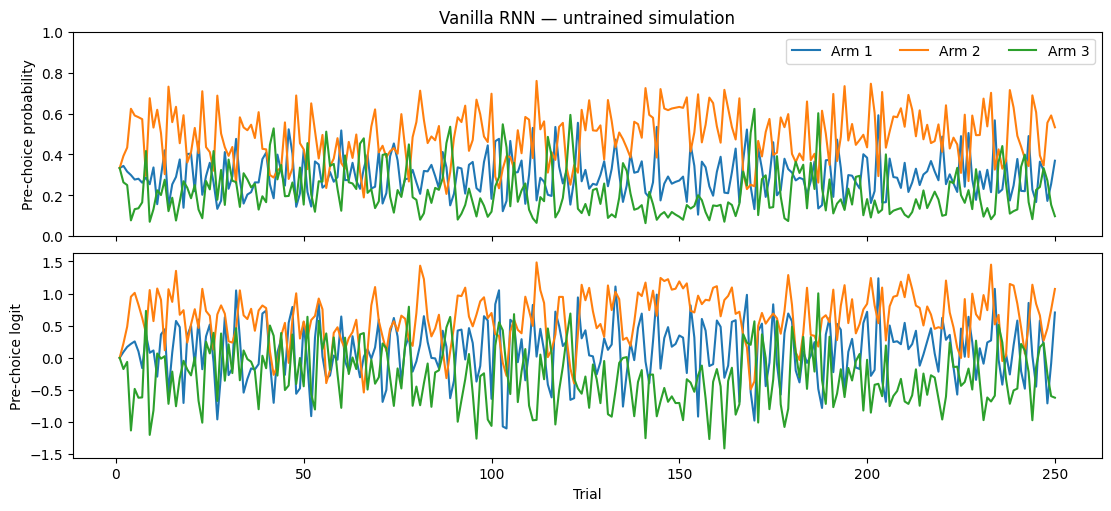

In [6]:
rnn_demo_sessions, rnn_demo_parameters = {}, {}
for model in NEURAL_MODELS:
    params = initialize_parameters(jax.random.PRNGKey(42), model, PAPER_CHOSEN[model]["hidden_units"])
    agent = NeuralBanditMouse(params, model, seed=42)
    numpy_state, python_state = np.random.get_state(), random.getstate()
    try:
        np.random.seed(42)
        random.seed(42)
        task = DriftingBanditTask([0, 1, 4], drift_rate=.1, swap_mode="most_chosen")
        sim_actions, sim_rewards, sim_values = task.simulate(agent, 250)
    finally:
        np.random.set_state(numpy_state)
        random.setstate(python_state)
    seq = dict(mouse="demo", problem=0, session=model, towers=[0, 1, 2],
               actions=np.asarray(sim_actions), rewards=np.asarray(sim_rewards, dtype=float))
    rnn_demo_parameters[model] = params
    rnn_demo_sessions[model] = seq
    trace = trace_sequence(params, seq, model)
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
    for arm in range(3):
        axes[0].plot(np.arange(1, 251), np.exp(trace["log_probabilities"][:, arm]), label=f"Arm {arm+1}")
        axes[1].plot(np.arange(1, 251), trace["logits"][:, arm], label=f"Arm {arm+1}")
    axes[0].set(title=f"{DISPLAY_NAMES[model]} — untrained simulation", ylabel="Pre-choice probability", ylim=(0, 1))
    axes[1].set(xlabel="Trial", ylabel="Pre-choice logit")
    axes[0].legend(ncol=3)
    plt.show()


## Optional synthetic training check

This is a small behavioral-cloning example, independent of the external data drive. Generate sessions from the existing Q-learning model for ten synthetic subjects, then fit all four neural architectures on an 80/10/10 subject split. Training and evaluation use observed histories, not simulated neural choices. A short run checks execution; it does not establish parameter recovery, data sufficiency, or a scientific architecture ranking. Network flexibility can make short-run validation selection favor initialization.


In [7]:
rnn_run_synthetic = False
if rnn_run_synthetic:
    synthetic_sequences = []
    numpy_state, python_state = np.random.get_state(), random.getstate()
    try:
        for subject in range(10):
            for session in range(2):
                seed = 1000+10*subject+session
                np.random.seed(seed)
                random.seed(seed)
                task = DriftingBanditTask([0, 1, 4], swap_mode="most_chosen")
                generator = QLearningMouse(3, .2, 2., .25)
                a, r, _ = task.simulate(generator, 100)
                synthetic_sequences.append(dict(mouse=f"synthetic-{subject}", problem=session,
                    session=f"ses-{session}", towers=[0, 1, 2], actions=np.asarray(a), rewards=np.asarray(r, dtype=float)))
    finally:
        np.random.set_state(numpy_state)
        random.setstate(python_state)
    rnn_synthetic_results = run_paper_sweep(
        synthetic_sequences, rnn_repo_root / "results/neural_bandit_synthetic",
        models=NEURAL_MODELS,
        grid=[dict(hidden_units=8, optimizer_learning_rate=1e-3, l2_weight=1e-5, batch_size=4)],
        n_seeds=1, max_steps=200, validation_every=50, profile="synthetic-smoke",
    )
    display(pd.DataFrame(rnn_synthetic_results["selected"]))
else:
    print("Set rnn_run_synthetic=True to run the standalone synthetic training example.")


Set rnn_run_synthetic=True to run the standalone synthetic training example.


## Cohort data: same histories and auditing as the RL notebook

The next setup/loading cells are independent of the RL notebook's kernel. They use its existing cohort-1 pipeline and ordinal problems 5–11, exclude magnitude/pretraining tasks, audit and exclude whole sessions with missing/invalid histories, retain zero rewards, and map physical tower identities to zero-based indices. Configure/mount `cohort_data_root` before loading. Population fits use all usable available sessions; they do not require every mouse to have all seven problems. This includes MY_71_N's available problems 5–10.

If `cohort_sequences` is already loaded in this kernel with these conventions, skip the loading cells. Both notebooks use split seed 42, so **the identical sequence dataset** gives identical training/validation/test mice. A different inclusion audit or sequence dataset may change split membership; compare the saved split identities and data hash, not just the seed.


In [8]:
# Independent cohort setup: no need to run the synthetic neural example first.
import importlib
import json
import sys
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cohort_repo_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/behavior_import").is_dir()), None
)
if cohort_repo_root is None:
    raise RuntimeError("Run this notebook from within the repository.")
if str(cohort_repo_root) not in sys.path:
    sys.path.insert(0, str(cohort_repo_root))

from src.agents.cohort_fitting import (
    prepare_cohort_sequences,
)
from src.behavior_import.extract_trials import extract_trials_grouped_by_problem
cohort_import = importlib.import_module("src.behavior_import.import_data")

# Match the existing cohort-1 analysis notebook. Mount the drive or edit this path.
cohort_data_root = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01")
cohort_problem_numbers = list(range(5, 12))
cohort_excluded_task_parts = ("mag", "pretraining")
cohort_fit_bounds = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]
cohort_fit_starts = 10
cohort_fit_seed = 42
cohort_output_root = cohort_repo_root / "results/cohort_01_parameter_fitting"
# Explicit exception: six folds for this mouse; seven for all others.
cohort_problem_overrides = {"MY_71_N": list(range(5, 11))}


In [ ]:
# Load all eligible sessions first: filtering to later sessions beforehand
# would change the pipeline's ordinal problem numbering.
if not cohort_data_root.is_dir():
    raise FileNotFoundError(
        f"Cohort 1 data not found: {cohort_data_root}. "
        "Mount the data drive or set cohort_data_root to the full cohort directory."
    )
cohort_files = cohort_import.collect_tsv_files(cohort_data_root.resolve())
cohort_eligible_files = []
cohort_file_rows = []
for path, frame in cohort_files:
    task_rows = frame.loc[
        frame["type"].eq("info") & frame["subtype"].eq("task_name"), "content"
    ]
    task_name = str(task_rows.iloc[0]) if len(task_rows) else None
    keep = task_name is not None and not any(
        part in task_name.casefold() for part in cohort_excluded_task_parts
    )
    cohort_file_rows.append({"path": str(path), "task_name": task_name, "included": keep})
    if keep:
        cohort_eligible_files.append((path, frame))
cohort_file_audit = pd.DataFrame(cohort_file_rows, columns=["path", "task_name", "included"])
display(cohort_file_audit.groupby(["task_name", "included"], dropna=False).size().rename("files"))
if not cohort_eligible_files:
    raise ValueError("No eligible task files remain; check the root and the task-name audit.")
with patch.object(cohort_import, "collect_tsv_files", return_value=cohort_eligible_files):
    cohort_raw = cohort_import.import_data(cohort_data_root)
cohort_all_problems = extract_trials_grouped_by_problem(cohort_raw, merge_recurring_problems=False)
print("Available pipeline problem numbers:", sorted(cohort_all_problems))
missing_problems = sorted(set(cohort_problem_numbers) - set(cohort_all_problems))
if missing_problems:
    raise ValueError(
        f"Missing requested pipeline problems: {missing_problems}. "
        "Check the complete cohort data and task filtering; problem numbers will not be relabelled."
    )
cohort_sequences, cohort_session_audit = prepare_cohort_sequences(
    cohort_all_problems, cohort_problem_numbers
)
display(cohort_session_audit.groupby(["mouse", "problem", "included"]).agg(
    sessions=("session", "size"), trials=("n_trials", "sum")
))
display(cohort_session_audit.loc[~cohort_session_audit.included])

[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-01_id-MY_71_N/ses-08_date-20260204/behav/._MY_71_N-2026-02-04-153602.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-155_date-20260613/behav/._MY_72_L-2026-06-13-201430.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-02_id-MY_71_L/ses-54_date-20260305/behav/._MY_71_L-2026-03-05-150416.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-04_id-MY_72_N/ses-40_date-20260225/behav/._MY_72_N-2026-02-25-143929.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/

task_name                                              included
Meg\3x3_field_blocked_reward_bandit_with_cue           True        316
Meg\3x3_field_drifting_value_bandit                    True        467
Meg\3x3_field_drifting_value_bandit_for_recording_71R  True        126
Meg\3x3_field_drifting_value_bandit_for_recording_72L  True         83
Name: files, dtype: int64

/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

[INFO] Processed 6 subjects(s), 882 session(s).
[INFO] Split MY_71_R ses-213_date-20260725 into 2 recording segments because the tower configuration changed.
[WARNING] No trial information found for subject MY_72_N, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_72_N, session ses-2_date-20260201
[WARNING] No trial information found for subject MY_72_N, session ses-3_date-20260202
[INFO] Merging multiple files for subject MY_72_N, session ses-8_date-20260204
[INFO] Merging multiple files for subject MY_72_N, session ses-9_date-20260205
[INFO] Merging multiple files for subject MY_72_N, session ses-42_date-20260226
[WARNING] No trial information found for subject MY_72_N, session ses-61_date-20260311
[WARNING] No trial information found for subject MY_72_L, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_72_L, session ses-2_date-20260201
[WARNING] No trial information found for subject MY_72_L, session ses-3_date-20260202
[

## Paper-style population fitting for all four architectures

The runner shares the RL notebook's population protocol: subject-disjoint 80/10/10 splits (mice here), one weight set per architecture shared across training mice, minibatch Adam in JAX/Optax, sessions sampled uniformly with replacement, complete within-session histories, masked padding, and resets per session. Models differ only in their defined architecture and the hyperparameters selected on validation data.

**Objective:** sum of observed-choice NLL across the sampled sessions/trials plus `l2_weight * sum(parameter_array**2)` over **all** trainable arrays, including biases, forgetting_raw and q_init. This is coupled L2 in Adam, not decoupled AdamW. The paper does not specify the regularized coordinates, bias inclusion, normalization, Adam defaults, initialization or validation cadence. These conventions match our paper-style RL fitter and are recorded in manifests; they affect the fitted representation and are not exact published-code replication. Optax Adam uses its default (.9, .999, epsilon 1e-8) moments, with no added scheduler or clipping.

**Full sweep:** the paper's optimizer learning rates [1e-3,1e-4,1e-5] × L2 weights [1e-3,1e-4,1e-5] × batch sizes [32,64,128] × hidden widths [16,32,64], five independent initializations per setting, each up to 1,000,000 updates. That is **81 settings × 5 seeds × 4 models = 1,620 runs**, or 1.62 billion optimizer updates. Hidden width is the same in both channels of each hybrid. The paper's chosen configurations (printed above) came from validation on its human task; our full sweep selects configurations on validation mice, not by copying those winners.

**Selection:** evaluate unregularized, pooled validation NLL per observed trial every 10,000 steps, including initialization at step zero. Select settings, seed and checkpoint separately per architecture using validation only. The paper's validation cadence/seed-selection aggregation is unspecified; this is our explicit convention. Test mice are scored **only after the entire configured sweep is complete**. A partial sweep yields progress but no test comparisons. All test histories update network states sequentially; they never update weights or choose a configuration.

**Pilot:** all four models, width 8, batch 4, one seed, 200 updates. This is an execution/runtime check, not the publication-budget sweep. Changing to full creates a separate experiment. Pilot test scores must not be used to choose the eventual profile, model settings or split and then represented as untouched test results.

**Data differences:** the paper trained on four-arm human tasks with 150 trials per block; here three-arm complete extracted mouse sessions have variable length and delivered reward pulses. Rewards are unscaled. Uniform session sampling and summed NLL let longer sessions and mice with more sessions contribute more training evidence. Validation/test summaries use trial weighting, with per-mouse summaries available separately. Reward units can change tanh saturation, gradient behavior and regularization's effect; any normalization must be specified and based on training data or known task constants, not inferred from test outcomes.

**Compared with per-mouse RL fitting:** these population networks test generalization to **unseen mice**, whereas the original RL cross-validation fits each mouse separately and tests unseen problems for that same mouse. Those scores answer different questions. For RL-versus-neural comparison, use the RL notebook's **population** procedure on the exact same sequence dataset, splits and metric definitions. Architecture size alone does not establish better fit; lower training loss is not evidence of improved held-out prediction.

**Saving/resume:** configuration, exact mouse identities, sequence hash, implementation source, library versions and initialization conventions are saved. Checkpoints include every parameter array, Adam moment, minibatch RNG, validation history and best validation iterate. Interrupt/re-execute to resume from the last saved checkpoint; no parameter updates since that checkpoint are guaranteed preserved. Completed runs are reused. Do not run the same experiment concurrently. Selected model weights are saved separately as `.npz` files, with summaries/counts shown in the notebook instead of dumping all weights.


In [ ]:
# Audit the common population split before training.
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup/loading cells first.")
rnn_parts, rnn_split_mice = split_by_mouse(cohort_sequences, seed=42)
rnn_split_audit = pd.DataFrame([
    dict(partition=part, mice=", ".join(rnn_split_mice[part]), n_mice=len(rnn_split_mice[part]),
         n_sessions=len(data), n_trials=sum(len(s["actions"]) for s in data))
    for part, data in rnn_parts.items()
])
display(rnn_split_audit)


In [ ]:
rnn_profile = "pilot"  # Change to "full" for the publication-budget sweep.
if rnn_profile == "pilot":
    rnn_fit_settings = dict(
        grid=[dict(hidden_units=8, optimizer_learning_rate=1e-3, l2_weight=1e-5, batch_size=4)],
        n_seeds=1, max_steps=200, validation_every=50,
    )
elif rnn_profile == "full":
    rnn_fit_settings = dict(
        grid=[dict(setting, hidden_units=width) for width in [16, 32, 64] for setting in FULL_GRID],
        n_seeds=5, max_steps=1_000_000, validation_every=10_000,
    )
else:
    raise ValueError("Choose pilot or full.")
rnn_total_runs = len(NEURAL_MODELS)*len(rnn_fit_settings["grid"])*rnn_fit_settings["n_seeds"]
print(f"{rnn_profile.upper()}: {rnn_total_runs:,} runs; "
      f"{rnn_total_runs*rnn_fit_settings['max_steps']:,} optimizer updates")


In [ ]:
# Explicit opt-in; re-execution resumes the same experiment.
rnn_run = False
rnn_max_new_runs = None  # Small integer limits newly completed runs; None finishes all.
if rnn_run:
    rnn_results = run_paper_sweep(
        cohort_sequences, rnn_repo_root / "results/paper_style_neural_fitting",
        models=NEURAL_MODELS, **rnn_fit_settings,
        split_seed=42, fit_seed=123, max_new_runs=rnn_max_new_runs, profile=rnn_profile,
    )
    print("COMPLETE" if rnn_results["complete"] else "PARTIAL",
          f"{rnn_results['completed_runs']}/{rnn_results['expected_runs']} runs", rnn_results["output_dir"])
    display(pd.DataFrame(rnn_results["selected"]))
else:
    print("Set rnn_run=True to run/resume the selected fitting profile.")


## Held-out metrics and model comparisons

Cross entropy = NLL / observed trials (nats/choice); lower is better. Uniform-choice baseline is log(3). `exp(-cross_entropy)` is the geometric mean probability assigned to the observed choices, **not** argmax percentage correct, despite the paper's “accuracy” terminology. Both are reported separately. Argmax ties choose the lowest indexed arm. Pooling NLL/trials weights trials; averaging the mouse-level CE column gives equal mouse weight. Sessions from the same mouse are not independent participants. The same held-out mice/sessions are used for all four fitted architectures; do not infer significance from the small test-mouse count or treat model seeds as independent animals.


In [ ]:
if rnn_run and "rnn_results" in globals() and rnn_results["complete"]:
    rnn_output = Path(rnn_results["output_dir"])
    rnn_test_sessions = pd.DataFrame(rnn_results["test_sessions"])
    rnn_test_sessions.to_csv(rnn_output / "test_sessions.csv", index=False)
    display(rnn_test_sessions)
    rnn_mouse_scores = rnn_test_sessions.groupby(["model", "mouse"]).agg(
        n_sessions=("session", "size"), n_trials=("n_trials", "sum"), nll=("nll", "sum"))
    rnn_mouse_scores["cross_entropy"] = rnn_mouse_scores.nll/rnn_mouse_scores.n_trials
    rnn_mouse_scores["geometric_mean_choice_probability"] = np.exp(-rnn_mouse_scores.cross_entropy)
    rnn_paired_scores = rnn_mouse_scores.cross_entropy.unstack("model")
    rnn_paired_scores["memory_improvement_over_vanilla"] = rnn_paired_scores.vanilla_rnn-rnn_paired_scores.memory_ann
    display(rnn_mouse_scores)
    display(rnn_paired_scores)
    print("Equal-mouse mean CE:", rnn_mouse_scores.cross_entropy.groupby("model").mean().to_dict())
    rnn_mouse_scores.to_csv(rnn_output / "test_mouse_scores.csv")
    rnn_paired_scores.to_csv(rnn_output / "test_paired_model_scores.csv")
else:
    print("No complete sweep from this run; held-out test comparisons are withheld.")


## Inspect a selected model and its state trajectories

Choose a model and a saved selected-weight file. Loading `.npz` uses `allow_pickle=False`. The trace includes pre-choice logits/probabilities, Q/c and hidden states, plus Q/c after observation. Inspecting test trajectories describes a selected model; using those observations to redesign or tune a model consumes the test set, so a subsequent evaluation needs new held-out data.

Hybrid plots show both Q and c contributions; their sum is the logit. The hidden-state plot shows vector **norms**, not inferred psychological quantities or uniquely identifiable neural dimensions. Vanilla RNN's unused hybrid channels remain zero placeholders in the unified state container and are not plotted/interpreted.


In [ ]:
rnn_inspect_model = "memory_ann"
if rnn_run and "rnn_results" in globals() and rnn_results["complete"]:
    chosen = next(row for row in rnn_results["selected"] if row["model"] == rnn_inspect_model)
    with np.load(Path(rnn_results["output_dir"])/chosen["parameters_file"], allow_pickle=False) as saved:
        inspected_parameters = {key: jnp.asarray(saved[key]) for key in saved.files}
    inspect_mouse = rnn_results["split_mice"]["test"][0]
    inspected_sequence = next(s for s in cohort_sequences if s["mouse"] == inspect_mouse)
    inspected_trace = trace_sequence(inspected_parameters, inspected_sequence, rnn_inspect_model)
    n = min(250, len(inspected_sequence["actions"]))
    trials = np.arange(1, n+1)
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
    for arm, tower in enumerate(inspected_sequence["towers"]):
        axes[0].plot(trials, np.exp(inspected_trace["log_probabilities"][:n, arm]), label=tower)
        axes[1].plot(trials, inspected_trace["logits"][:n, arm], label=f"{tower}: logit")
        if rnn_inspect_model != "vanilla_rnn":
            axes[1].plot(trials, inspected_trace["pre_q"][:n, arm], linestyle="--", alpha=.6, label=f"{tower}: Q")
            axes[1].plot(trials, inspected_trace["pre_c"][:n, arm], linestyle=":", alpha=.6, label=f"{tower}: c")
    hidden_channels = ["joint"] if rnn_inspect_model == "vanilla_rnn" else ["reward", "action"]
    for channel in hidden_channels:
        axes[2].plot(trials, np.linalg.norm(inspected_trace[f"pre_{channel}_hidden"][:n], axis=1), label=channel)
    axes[0].set(title=f"{DISPLAY_NAMES[rnn_inspect_model]} · {inspect_mouse} · {inspected_sequence['session']}",
                ylabel="Pre-choice probability", ylim=(0, 1))
    axes[1].set_ylabel("Logit / channel contribution")
    axes[2].set(xlabel="Trial", ylabel="Hidden-state norm")
    for ax in axes:
        ax.legend(ncol=3, fontsize=8)
    plt.show()
else:
    print("Complete a configured sweep before inspecting its selected models.")


## Controlled reward-function probes

For RL-ANN, vary reward and prior chosen Q. For Context-ANN, also fix unchosen Q context (the chosen context entry is changed consistently with the chosen Q input). For Memory-ANN, vary reward while holding reward memory at a specified vector; chosen Q is not an input. The helper returns the chosen value **after** our explicit forgetting operation, so its output matches state-update timing.

The example below uses **training** rewards and traced training states to choose the displayed domain/reference states. It does not infer normalization from held-out rewards. A mean hidden state or mean Q vector is a descriptive reference, not necessarily a state the network visits. A finite probe curve does not prove global monotonicity, unique computation, a causal psychological mechanism, or equality to the published model. Vanilla RNN has no independent reward module to extract.


In [ ]:
if rnn_run and "rnn_results" in globals() and rnn_results["complete"] and rnn_inspect_model != "vanilla_rnn":
    train_mice = set(rnn_results["split_mice"]["train"])
    training_sequences = [s for s in cohort_sequences if s["mouse"] in train_mice]
    training_rewards = np.concatenate([s["rewards"] for s in training_sequences])
    reference_sequence = training_sequences[0]
    reference_trace = trace_sequence(inspected_parameters, reference_sequence, rnn_inspect_model)
    probe_rewards = np.linspace(training_rewards.min(), training_rewards.max(), 100)
    if rnn_inspect_model == "memory_ann":
        hidden_reference = reference_trace["pre_reward_hidden"].mean(axis=0)
        curves = probe_reward_module(inspected_parameters, rnn_inspect_model, probe_rewards,
                                    reward_hidden=hidden_reference)
        labels = ["Mean reward state from one training session"]
    else:
        chosen_values = np.quantile(reference_trace["pre_q"], [.1, .5, .9])
        curves = probe_reward_module(inspected_parameters, rnn_inspect_model, probe_rewards,
            chosen_values=chosen_values, context=reference_trace["pre_q"].mean(axis=0))
        labels = [f"Chosen Q={v:.3g}" for v in chosen_values]
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    for curve, label in zip(curves, labels):
        ax.plot(probe_rewards, curve, label=label)
    ax.set(xlabel="Received reward (pulses)", ylabel="Updated chosen Q (after forgetting)",
           title=f"{DISPLAY_NAMES[rnn_inspect_model]}: controlled reward probe")
    ax.legend(fontsize=8)
    plt.show()
else:
    print("Select a fitted hybrid model to inspect its independent reward module.")
